In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [10]:
# Define the dataset path
DATA_PATH = Path("../data/raw/fake reviews dataset.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display first 5 rows
df.head()

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [24]:
print("Dataset shape:", df.shape)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(df.info())
print(df.describe(include="all"))
pd.set_option("display.max_colwidth", 200)

df[["category", "rating", "label", "text_"]].head(10)

Dataset shape: (40432, 4)
Number of rows: 40432
Number of columns: 4
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB
None
              category        rating  label  \
count            40432  40432.000000  40432   
unique              10           NaN      2   
top     Kindle_Store_5           NaN     CG   
freq              4730           NaN  20216   
mean               NaN      4.256579    NaN   
std                NaN      1.144354    NaN   
min                NaN      1.000000    NaN   
25%                NaN      4.000000    NaN   
50%                NaN      5.000000    NaN   
75%                NaN      5.000000    NaN   
max            

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfortable. I love it!Very pretty"
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I've had mine for a couple of years"
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and feel of this pillow.
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it is a great product for the price! I"
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the set for two months now and have not been
5,Home_and_Kitchen_5,3.0,CG,I WANTED DIFFERENT FLAVORS BUT THEY ARE NOT.
6,Home_and_Kitchen_5,5.0,CG,They are the perfect touch for me and the only thing I wish they had a little more space.
7,Home_and_Kitchen_5,3.0,CG,These done fit well and look great. I love the smoothness of the edges and the extra
8,Home_and_Kitchen_5,5.0,CG,"Great big numbers & easy to read, the only thing I didn't like is the size of the"
9,Home_and_Kitchen_5,5.0,CG,My son loves this comforter and it is very well made. We also have a baby


In [25]:
# Count missing values in every column
print(df.isnull().sum())

# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentages:")
print(missing_percentage)

category    0
rating      0
label       0
text_       0
dtype: int64

Missing value percentages:
category    0.0
rating      0.0
label       0.0
text_       0.0
dtype: float64


Label distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64
--------------------------------------------------
Label percentages:
label
CG    50.0
OR    50.0
Name: proportion, dtype: float64


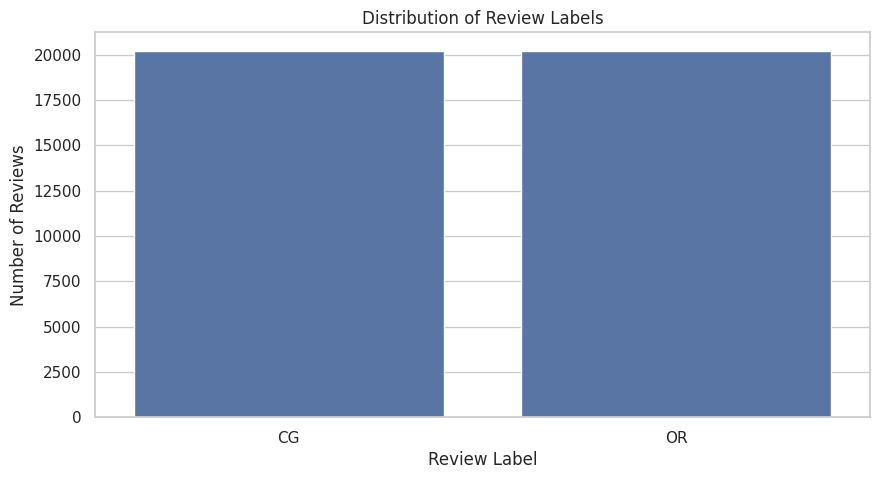

In [41]:
print("Label distribution:")
print(df["label"].value_counts())
print("-"*50)
print("Label percentages:")
print(df["label"].value_counts(normalize=True) * 100)
sns.countplot(data=df, x="label")

plt.title("Distribution of Review Labels")
plt.xlabel("Review Label")
plt.ylabel("Number of Reviews")
plt.savefig(
    "../results/figures/label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [54]:
# Check completely duplicated rows
print("Completely duplicated rows:", df.duplicated().sum())

# Check duplicate review texts before normalization
raw_text = df["text_"].astype("string")

print(
    "Duplicate review texts (raw):",
    raw_text.duplicated().sum()
)

# Remove leading and trailing whitespace
normalized_text = raw_text.str.strip()

print(
    "Duplicate review texts (after stripping whitespace):",
    normalized_text.duplicated().sum()
)

# Check whether normalized duplicate texts have conflicting labels
duplicate_label_check = (
    pd.DataFrame({
        "text": normalized_text,
        "label": df["label"]
    })
    .groupby("text")["label"]
    .nunique()
)

conflicting_duplicates = duplicate_label_check[
    duplicate_label_check > 1
]

print(
    "Normalized review texts with conflicting labels:",
    len(conflicting_duplicates)
)

Completely duplicated rows: 12
Duplicate review texts (raw): 20
Duplicate review texts (after stripping whitespace): 22
Normalized review texts with conflicting labels: 0


In [53]:
empty_reviews = (
    df["text_"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Empty reviews:", empty_reviews)

Empty reviews: 0


category
Kindle_Store_5                  4730
Books_5                         4370
Pet_Supplies_5                  4254
Home_and_Kitchen_5              4056
Electronics_5                   3988
Sports_and_Outdoors_5           3946
Tools_and_Home_Improvement_5    3858
Clothing_Shoes_and_Jewelry_5    3848
Toys_and_Games_5                3794
Movies_and_TV_5                 3588
Name: count, dtype: int64


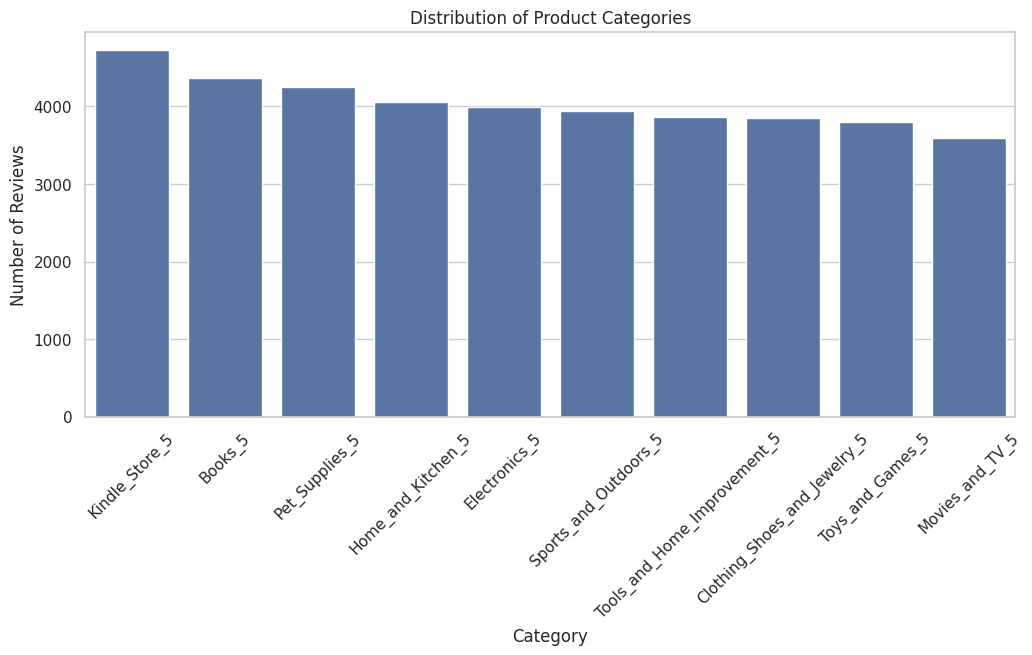

In [42]:
print(df["category"].value_counts())

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Distribution of Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.savefig(
    "../results/figures/product_categories_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

rating
1.0     2155
2.0     1967
3.0     3786
4.0     7965
5.0    24559
Name: count, dtype: int64


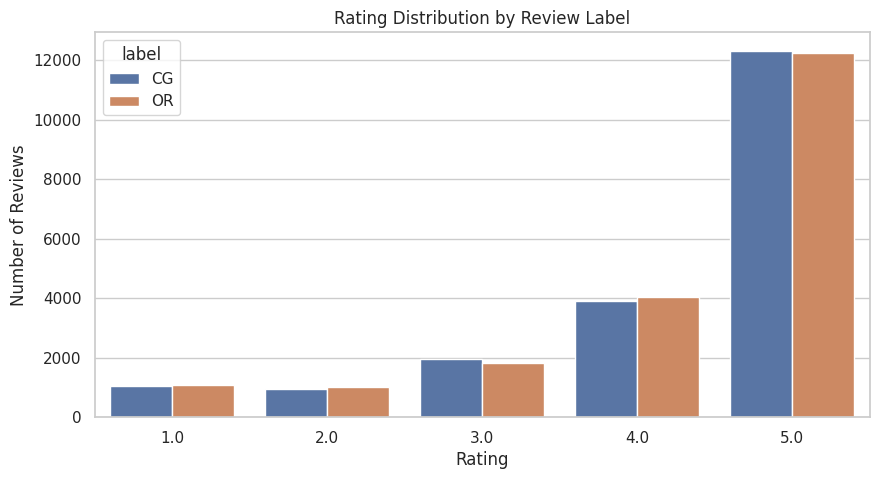

In [47]:
print(df["rating"].value_counts().sort_index())

sns.countplot(
    data=df,
    x="rating",
    hue="label"
)

plt.title("Rating Distribution by Review Label")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.savefig(
    "../results/figures/rating_distribution_by_label.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

label                           CG    OR
category                                
Books_5                       50.0  50.0
Clothing_Shoes_and_Jewelry_5  50.0  50.0
Electronics_5                 50.0  50.0
Home_and_Kitchen_5            50.0  50.0
Kindle_Store_5                50.0  50.0
Movies_and_TV_5               50.0  50.0
Pet_Supplies_5                50.0  50.0
Sports_and_Outdoors_5         50.0  50.0
Tools_and_Home_Improvement_5  50.0  50.0
Toys_and_Games_5              50.0  50.0


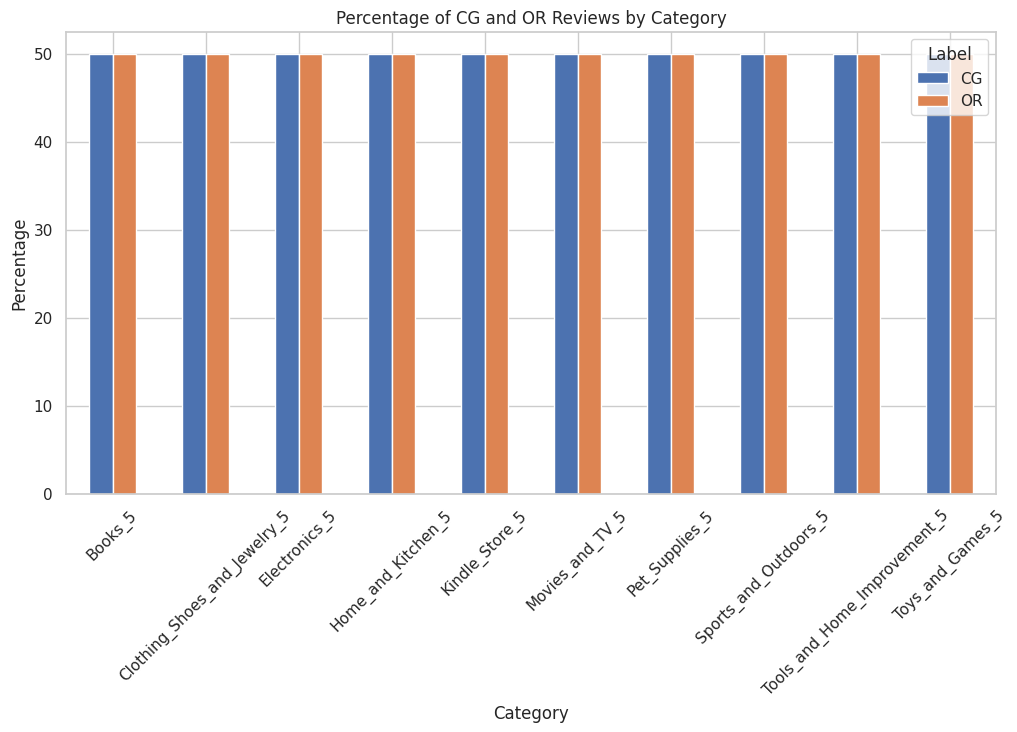

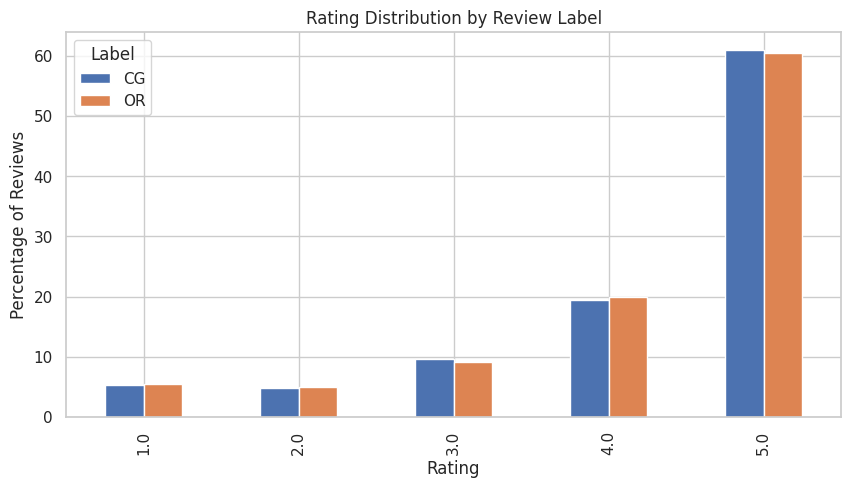

In [49]:
category_label = pd.crosstab(
    df["category"],
    df["label"],
    normalize="index"
) * 100

print(category_label.round(2))

category_label.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Percentage of CG and OR Reviews by Category")
plt.xlabel("Category")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(title="Label")
plt.savefig(
    "../results/figures/perentage_cg_or_by_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
rating_distribution = pd.crosstab(
    df["rating"],
    df["label"],
    normalize="columns"
) * 100

rating_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Rating Distribution by Review Label")
plt.xlabel("Rating")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Label")
plt.savefig(
    "../results/figures/rating_distribution_by_review_label.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

      character_count                                                     \
                count        mean         std   min    25%    50%    75%   
label                                                                      
CG            20216.0  305.573506  307.037430  24.0   96.0  174.0  383.0   
OR            20216.0  396.970419  418.428047  28.0  121.0  224.0  498.0   

              word_count                                                      
          max      count       mean        std  min   25%   50%   75%    max  
label                                                                         
CG     1717.0    20216.0  61.288237  61.799015  1.0  19.0  35.0  77.0  318.0  
OR     2827.0    20216.0  73.642610  76.078420  5.0  23.0  42.0  93.0  373.0  


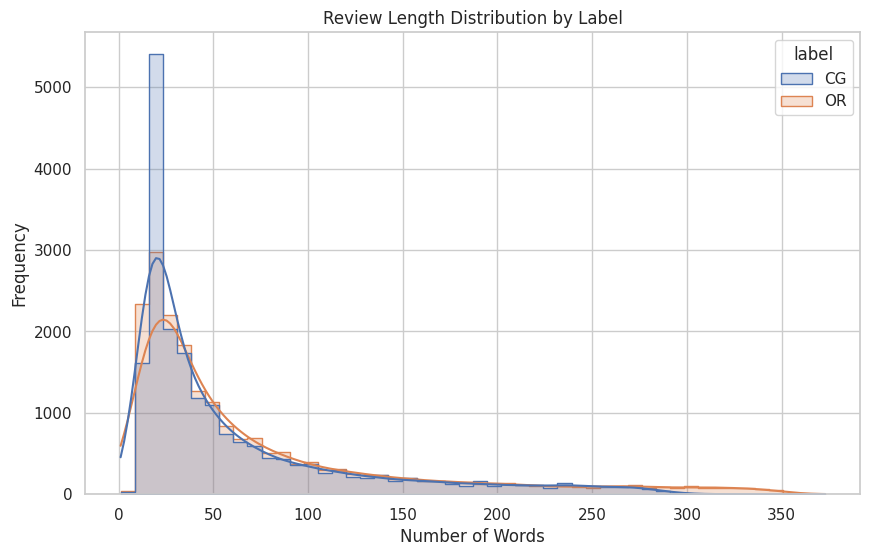

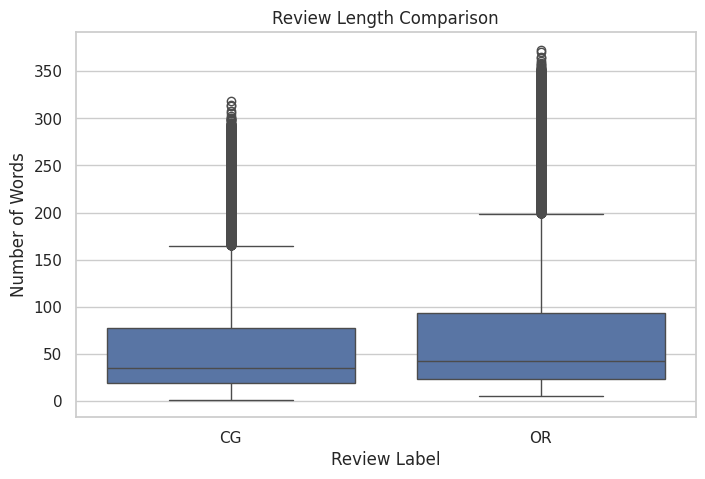

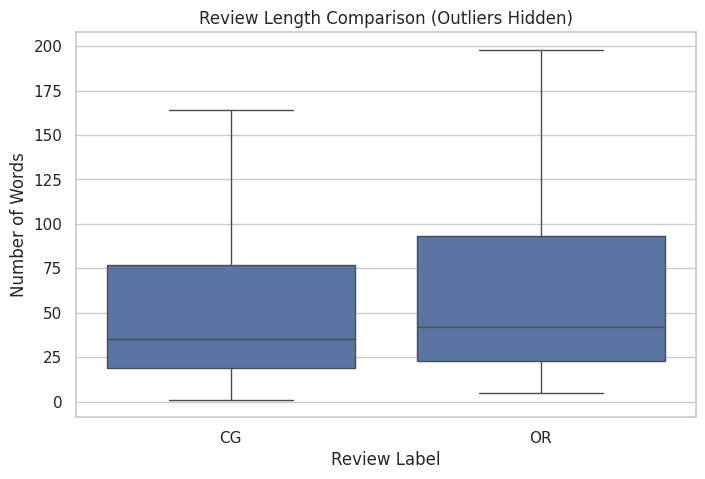

In [51]:
# Calculate character and word counts
df["character_count"] = df["text_"].fillna("").astype(str).str.len()

df["word_count"] = (
    df["text_"].fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Statistical summary
print(
    df.groupby("label")[["character_count", "word_count"]]
    .describe()
)
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Review Length Distribution by Label")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.savefig(
    "../results/figures/review_length_distribution_by_label.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count"
)

plt.title("Review Length Comparison")
plt.xlabel("Review Label")
plt.ylabel("Number of Words")
plt.savefig(
    "../results/figures/review_length_comparison_by_label.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    showfliers=False
)

plt.title("Review Length Comparison (Outliers Hidden)")
plt.xlabel("Review Label")
plt.ylabel("Number of Words")
plt.savefig(
    "../results/figures/review_length_comparison_by_label(outliers_hidden).png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Key Findings from Exploratory Data Analysis

1. The dataset contains 40,432 reviews across 10 product categories.
2. The CG and OR classes are perfectly balanced, with 20,216 reviews in each class.
3. Every product category contains an equal proportion of CG and OR reviews. Therefore, product category alone is unlikely to be a useful predictor of the target label.
4. Most reviews have a rating of 5, and the rating distributions of the two classes appear broadly similar.
5. OR reviews are generally longer than CG reviews. The median word counts are 42 and 35 respectively. However, the distributions overlap considerably, suggesting that review length alone is insufficient for reliable classification.
6. The dataset contains 20 duplicated review texts, which must be considered when designing the training and testing splits.

### Implications for Modelling

The exploratory analysis suggests that textual features may contain useful information for distinguishing CG from OR reviews. We will investigate this using TF-IDF representations and machine learning classifiers. We will also ensure that duplicated reviews do not cause data leakage between training and testing sets.